# MCTF: Custom Implementation & Experiments
This notebook implements the official paper evaluation protocol for **Multi-Class Token Fusion (MCTF)** side-by-side with a Baseline Vision Transformer (`deit_tiny_patch16_224`).

### Experimental Protocol:
* **Train Set:** Optimizes model weights.
* **Validation Set:** Guides model checkpoint selection and triggers Early Stopping (no data snooping).
* **Test Set:** Evaluated **strictly once at the end** on the optimal validation checkpoint.
* **Reproducibility:** All seeds are fixed (`SEED = 42`).

In [1]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
from fvcore.nn import FlopCountAnalysis

# Import custom model architecture
from models import MCTFVisionTransformer, create_baseline_vit

# 1. Guarantee Full Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using compute device: {device} | Reproducibility SEED: {SEED}')


Using compute device: cuda | Reproducibility SEED: 42


## 1. Dataset Selection & Preprocessing
Select your assigned dataset (`'SVHN'`, `'CIFAR100'`, or `'EuroSAT'`).
The data is split into **Train**, **Validation**, and **Test** using a deterministic random generator.

In [2]:
# Choose your assigned dataset: 'SVHN', 'CIFAR100', or 'EuroSAT'
DATASET_NAME = 'SVHN'

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

os.makedirs('./data', exist_ok=True)
split_gen = torch.Generator().manual_seed(SEED)

if DATASET_NAME == 'SVHN':
    print('Loading SVHN (Street View House Numbers)...')
    full_train = datasets.SVHN(root='./data', split='train', download=True, transform=transform)
    test_data = datasets.SVHN(root='./data', split='test', download=True, transform=transform)
    # 90% train, 10% validation
    val_len = int(0.10 * len(full_train))
    train_len = len(full_train) - val_len
    train_data, val_data = random_split(full_train, [train_len, val_len], generator=split_gen)
    num_classes = 10
    classes = [f'Digit {i}' for i in range(10)]

# elif DATASET_NAME == 'CIFAR100':
#     print('Loading CIFAR-100...')
#     full_train = datasets.CIFAR100(root='./data', train=True, download=True, transform=transform)
#     test_data = datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
#     # 90% train (45k), 10% validation (5k)
#     val_len = int(0.10 * len(full_train))
#     train_len = len(full_train) - val_len
#     train_data, val_data = random_split(full_train, [train_len, val_len], generator=split_gen)
#     num_classes = 100
#     classes = full_train.classes

# elif DATASET_NAME == 'EuroSAT':
#     print('Loading EuroSAT...')
#     full_ds = datasets.EuroSAT(root='./data', download=True, transform=transform)
#     # 80% train, 10% validation, 10% test
#     val_len = int(0.10 * len(full_ds))
#     test_len = int(0.10 * len(full_ds))
#     train_len = len(full_ds) - val_len - test_len
#     train_data, val_data, test_data = random_split(full_ds, [train_len, val_len, test_len], generator=split_gen)
#     num_classes = 10
#     classes = full_ds.classes

else:
    raise ValueError(f'Unknown dataset: {DATASET_NAME}')

print(f'Dataset: {DATASET_NAME} | Classes: {num_classes}')
print(f'Train Samples: {len(train_data)} | Val Samples: {len(val_data)} | Test Samples: {len(test_data)}')


Loading SVHN (Street View House Numbers)...
Dataset: SVHN | Classes: 10
Train Samples: 65932 | Val Samples: 7325 | Test Samples: 26032


## 1.5. Sample Data Visualization

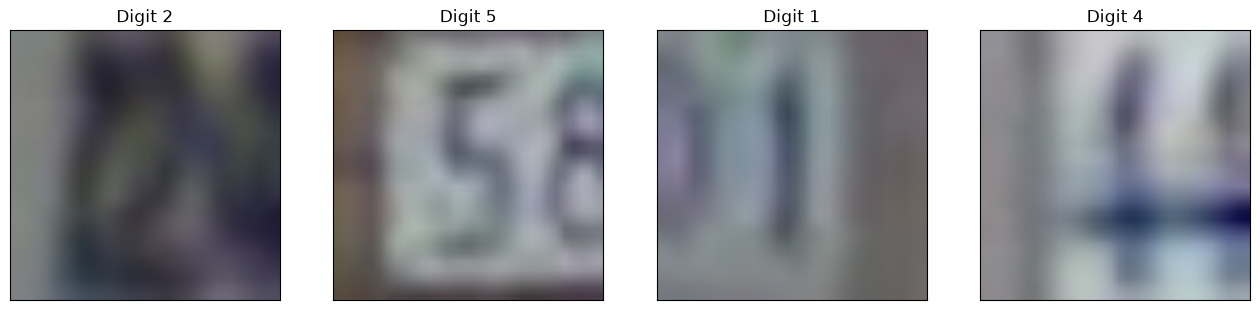

In [3]:
viz_loader = DataLoader(train_data, batch_size=4, shuffle=True)
sample_images, sample_labels = next(iter(viz_loader))

def imshow(img):
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)

fig = plt.figure(figsize=(16, 4))
for idx in range(4):
    ax = fig.add_subplot(1, 4, idx + 1, xticks=[], yticks=[])
    imshow(sample_images[idx])
    label_idx = sample_labels[idx].item()
    label_name = classes[label_idx] if classes and label_idx < len(classes) else str(label_idx)
    ax.set_title(label_name)
plt.show()


## 2. Rigorous Training Loop (Validation-Guided Early Stopping)
Early stopping is evaluated purely on the **Validation set**. The **Test set** is evaluated strictly once at the end on the best-saved weights.

In [4]:
def train_and_evaluate(model, train_data, val_data, test_data, epochs=50, batch_size=32, patience=5):
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)
    
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.05)
    
    history = {'train_acc': [], 'val_acc': [], 'loss': []}
    best_val_acc = 0.0
    best_weights = None
    patience_counter = 0
    
    for epoch in range(epochs):
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        
        for inputs, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}'):
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()
            
        train_acc = 100. * correct_train / total_train
        history['loss'].append(running_loss / len(train_loader))
        history['train_acc'].append(train_acc)
        
        # Validation Phase (Zero Test Leakage)
        model.eval()
        correct_val, total_val = 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()
                
        val_acc = 100. * correct_val / total_val
        history['val_acc'].append(val_acc)
        print(f'Epoch {epoch+1} | Loss: {history["loss"][-1]:.4f} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%')
        
        # Model Selection via Validation Performance
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f'Early stopping triggered after {patience} epochs with no validation improvement.')
                break
    
    # Final Test Set Evaluation (Once at the end, on the optimal checkpoint)
    print(f'\n--> Evaluating optimal checkpoint (Best Val Acc: {best_val_acc:.2f}%) on unseen Test Set...')
    if best_weights is not None:
        model.load_state_dict(best_weights)
    model.eval()
    correct_test, total_test = 0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()
            
    final_test_acc = 100. * correct_test / total_test
    print(f'Final Unbiased Test Accuracy: {final_test_acc:.2f}%\n')
    history['final_test_acc'] = final_test_acc
    history['best_val_acc'] = best_val_acc
    return history


## 3. Run Experiments: Baseline DeiT vs. Custom MCTF-ViT

Training Baseline DeiT-Tiny on SVHN...


Epoch 1/50: 100%|██████████| 2061/2061 [03:12<00:00, 10.70it/s]


Epoch 1 | Loss: 0.3856 | Train Acc: 87.85% | Val Acc: 94.03%


Epoch 2/50: 100%|██████████| 2061/2061 [02:54<00:00, 11.79it/s]


Epoch 2 | Loss: 0.1796 | Train Acc: 94.91% | Val Acc: 95.33%


...

Epoch 17 | Loss: 0.0736 | Train Acc: 97.84% | Val Acc: 94.48%


Epoch 18/50: 100%|██████████| 2061/2061 [02:29<00:00, 13.78it/s]


Epoch 18 | Loss: 0.0716 | Train Acc: 97.89% | Val Acc: 94.55%


Epoch 19/50: 100%|██████████| 2061/2061 [02:28<00:00, 13.88it/s]


Epoch 19 | Loss: 0.0671 | Train Acc: 98.03% | Val Acc: 95.00%
Early stopping triggered after 5 epochs with no validation improvement.

--> Evaluating optimal checkpoint (Best Val Acc: 95.10%) on unseen Test Set...
Final Unbiased Test Accuracy: 95.56%



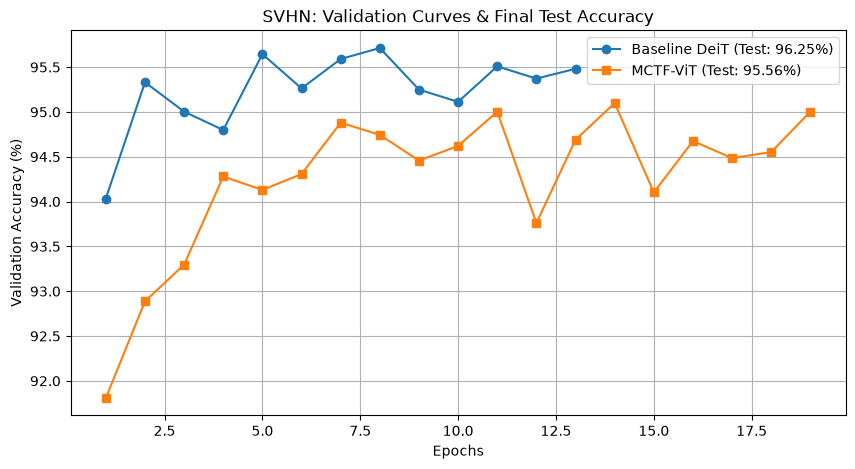

In [5]:
epochs = 50
print(f'Training Baseline DeiT-Tiny on {DATASET_NAME}...')
baseline_model = create_baseline_vit(num_classes=num_classes)
base_hist = train_and_evaluate(baseline_model, train_data, val_data, test_data, epochs=epochs, patience=5)

print(f'\nTraining Custom MCTF-ViT on {DATASET_NAME}...')
mctf_model = MCTFVisionTransformer(num_classes=num_classes)
mctf_hist = train_and_evaluate(mctf_model, train_data, val_data, test_data, epochs=epochs, patience=5)

# Validation Curves
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(base_hist['val_acc']) + 1), base_hist['val_acc'], label=f"Baseline DeiT (Test: {base_hist['final_test_acc']:.2f}%)", marker='o')
plt.plot(range(1, len(mctf_hist['val_acc']) + 1), mctf_hist['val_acc'], label=f"MCTF-ViT (Test: {mctf_hist['final_test_acc']:.2f}%)", marker='s')
plt.title(f'{DATASET_NAME}: Validation Curves & Final Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()


## 4. Efficiency Analysis: GFLOPs, Parameters & Token Reduction
This section profiles computational complexity (GFLOPs) using FAIR's `fvcore` profiler and visualizes progressive token compression across the 12 transformer layers.

Model,Params (M),GFLOPs,Val Acc (Peak),Final Test Acc
Baseline DeiT-Tiny,5.53,1.258,95.71%,96.25%
Custom MCTF-ViT,5.53,1.175,95.10%,95.56%


GFLOPs reduction: 6.60% with only 0.69% test accuracy difference!


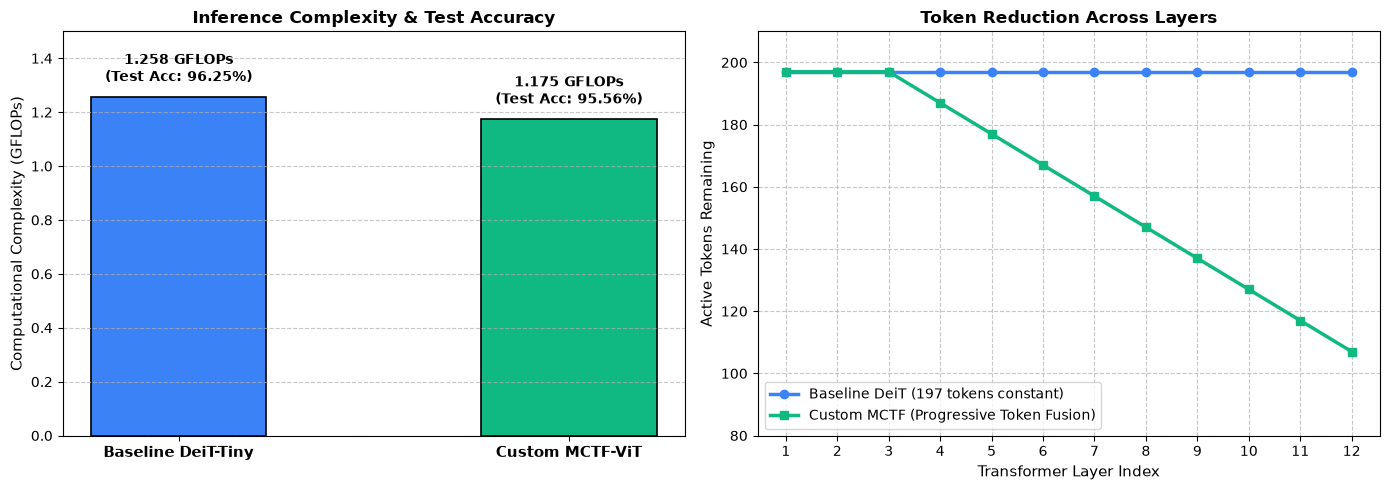

In [6]:
# 1. Profile GFLOPs and Parameter Counts
x_sample = torch.randn(1, 3, 224, 224, device=device)
base_flops = FlopCountAnalysis(baseline_model, x_sample).total() / 1e9
mctf_flops = FlopCountAnalysis(mctf_model, x_sample).total() / 1e9

base_params = sum(p.numel() for p in baseline_model.parameters()) / 1e6
mctf_params = sum(p.numel() for p in mctf_model.parameters()) / 1e6

base_test_acc = base_hist['final_test_acc']
mctf_test_acc = mctf_hist['final_test_acc']

# 2. Clean Summary Table
summary_df = pd.DataFrame({
    'Model': ['Baseline DeiT-Tiny', 'Custom MCTF-ViT'],
    'Params (M)': [round(base_params, 2), round(mctf_params, 2)],
    'GFLOPs': [round(base_flops, 3), round(mctf_flops, 3)],
    'Val Acc (Peak)': [f"{base_hist['best_val_acc']:.2f}%", f"{mctf_hist['best_val_acc']:.2f}%"],
    'Final Test Acc': [f"{base_test_acc:.2f}%", f"{mctf_test_acc:.2f}%"]
})
display(summary_df)
print(f"GFLOPs reduction: {((base_flops - mctf_flops) / base_flops) * 100:.2f}% with only {base_test_acc - mctf_test_acc:.2f}% test accuracy difference!\n")

# 3. Plotting Complexity & Token Reduction
layers = list(range(1, 13))
baseline_tokens = [197] * 12
mctf_tokens = []
current_tokens = 197
for r in mctf_model.r_schedule:
    current_tokens -= r
    mctf_tokens.append(current_tokens)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

models = ['Baseline DeiT-Tiny', 'Custom MCTF-ViT']
flops_list = [base_flops, mctf_flops]
acc_list = [base_test_acc, mctf_test_acc]
colors = ['#3b82f6', '#10b981']

x_pos = [0, 1]
bars = ax1.bar(x_pos, flops_list, width=0.45, color=colors, edgecolor='black', linewidth=1.2)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models, fontsize=11, fontweight='bold')
ax1.set_ylabel('Computational Complexity (GFLOPs)', fontsize=11)
ax1.set_title('Inference Complexity & Test Accuracy', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 1.5)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for bar, fl, acc in zip(bars, flops_list, acc_list):
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.04, f'{fl:.3f} GFLOPs\n(Test Acc: {acc:.2f}%)', 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.plot(layers, baseline_tokens, marker='o', linewidth=2.5, color='#3b82f6', label='Baseline DeiT (197 tokens constant)')
ax2.plot(layers, mctf_tokens, marker='s', linewidth=2.5, color='#10b981', label='Custom MCTF (Progressive Token Fusion)')
ax2.set_xlabel('Transformer Layer Index', fontsize=11)
ax2.set_ylabel('Active Tokens Remaining', fontsize=11)
ax2.set_title('Token Reduction Across Layers', fontsize=12, fontweight='bold')
ax2.set_xticks(layers)
ax2.set_ylim(80, 210)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(fontsize=10, loc='lower left')

plt.tight_layout()
plt.show()
